# 1 Environment Setup

In [1]:
import sys
from pathlib import Path
project_root = Path.cwd().resolve().parent
sys.path.insert(0, str(project_root))
print(f"Using project root: {project_root}\n Please verify path is correct.")
print("Not required if package installed in editable mode via 'pip install -e .'")

Using project root: /home/mbz/Documents/PhD
 Please verify path is correct.
Not required if package installed in editable mode via 'pip install -e .'


In [2]:
from src.config import PipelineConfig
from src.pipeline import SensorPipeline
from src.logging_utils import setup_logging
config = PipelineConfig.from_yaml(Path("config/sensors.yaml"))
print(f"Loaded {len(config.sensors)} sensors:")
for s in config.sensors:
    print(f"  - {s.name} ({s.sensor_type}, altitude: {s.altitude_m}m)")
setup_logging(config.log_dir, log_name="notebook_run")
pipeline = SensorPipeline(config, force=False)

2026-02-15 23:36:04,886 - root - INFO - Logging initialized. Log file: /home/mbz/Documents/PhD/SCD41_DATA/output/logs/notebook_run_20260215_233604.log


Loaded 5 sensors:
  - CO2_SCT1_2M (scd41, altitude: 2m)
  - CO2_30M_A (scd41, altitude: 30m)
  - CO2_30M_B (scd41, altitude: 30m)
  - CO2_30M_C (scd41, altitude: 30m)
  - LGR_30M (lgr_csv, altitude: 30m)


# 2 Process Raw Measurements

### todo:
- investigate faulty qc flag assignment
- - collect 2025 11, 12 raw data from smear
- process 2024, 2025 

In [3]:
# Process 2024 months (adjust as needed)
# for mo in [11, 12]:
for mo in [9, 10, 11]:
    print(f"\n{'='*30}")
    print(f"Processing 2024-{mo:02d}")
    print(f"{'='*30}")
    pipeline.run_all(year=2024, month=mo)

2026-02-15 18:57:22,533 - src.pipeline - INFO - Starting pipeline for all sensors
2026-02-15 18:57:22,534 - src.pipeline - INFO - ============================================================
2026-02-15 18:57:22,534 - src.pipeline - INFO - Processing sensor: CO2_SCT1_2M
2026-02-15 18:57:22,535 - src.pipeline - INFO - ============================================================
2026-02-15 18:57:22,616 - src.pipeline - INFO - Found 19 days ((2024, 9, 12) to (2024, 9, 30))
2026-02-15 18:57:22,617 - src.processor - INFO - Processing 2024-09-12 (13 files)
2026-02-15 18:57:22,623 - src.parsers.scd41_parser - INFO - QC flags: 22/22 samples (100.0%)
2026-02-15 18:57:22,627 - src.parsers.scd41_parser - INFO - QC flags: 28/28 samples (100.0%)



Processing 2024-09


2026-02-15 18:57:22,857 - src.parsers.scd41_parser - INFO - QC flags: 4291/4291 samples (100.0%)
2026-02-15 18:57:23,077 - src.parsers.scd41_parser - INFO - QC flags: 4302/4302 samples (100.0%)
2026-02-15 18:57:23,295 - src.parsers.scd41_parser - INFO - QC flags: 4314/4314 samples (100.0%)
2026-02-15 18:57:23,556 - src.parsers.scd41_parser - INFO - QC flags: 4314/4314 samples (100.0%)
2026-02-15 18:57:23,765 - src.parsers.scd41_parser - INFO - QC flags: 4311/4311 samples (100.0%)
2026-02-15 18:57:23,976 - src.parsers.scd41_parser - INFO - QC flags: 4314/4314 samples (100.0%)
2026-02-15 18:57:24,183 - src.parsers.scd41_parser - INFO - QC flags: 4314/4314 samples (100.0%)
2026-02-15 18:57:24,390 - src.parsers.scd41_parser - INFO - QC flags: 4317/4317 samples (100.0%)
2026-02-15 18:57:24,595 - src.parsers.scd41_parser - INFO - QC flags: 4311/4311 samples (100.0%)
2026-02-15 18:57:24,801 - src.parsers.scd41_parser - INFO - QC flags: 4314/4314 samples (100.0%)
2026-02-15 18:57:25,007 - src.


Processing 2024-10


2026-02-15 19:00:14,469 - src.processor - INFO - Removed 71891 duplicate timestamps
2026-02-15 19:00:14,473 - src.uptime - WARNING - Unexpected sample interval: 4.0s (expected ~60s)
2026-02-15 19:00:14,552 - src.processor - INFO - ✓ 2024-10-01: 31512 raw → 144 10-min samples (uptime: 100.0%)
2026-02-15 19:00:14,559 - src.processor - INFO - Processing 2024-10-02 (24 files)
2026-02-15 19:00:24,399 - src.processor - INFO - Removed 75893 duplicate timestamps
2026-02-15 19:00:24,403 - src.uptime - WARNING - Unexpected sample interval: 4.0s (expected ~60s)
2026-02-15 19:00:24,455 - src.processor - INFO - ✓ 2024-10-02: 27396 raw → 144 10-min samples (uptime: 100.0%)
2026-02-15 19:00:24,460 - src.processor - INFO - Processing 2024-10-03 (24 files)
2026-02-15 19:00:30,846 - src.processor - INFO - Removed 79970 duplicate timestamps
2026-02-15 19:00:30,849 - src.uptime - WARNING - Unexpected sample interval: 4.0s (expected ~60s)
2026-02-15 19:00:30,888 - src.processor - INFO - ✓ 2024-10-03: 23307


Processing 2024-11


2026-02-15 19:12:11,955 - src.processor - INFO - Removed 68470 duplicate timestamps
2026-02-15 19:12:11,961 - src.uptime - WARNING - Unexpected sample interval: 2.0s (expected ~60s)
2026-02-15 19:12:12,005 - src.processor - INFO - ✓ 2024-11-01: 33595 raw → 140 10-min samples (uptime: 100.0%)
2026-02-15 19:12:12,011 - src.processor - INFO - Processing 2024-11-02 (24 files)
2026-02-15 19:12:17,132 - src.processor - INFO - Removed 68459 duplicate timestamps
2026-02-15 19:12:17,135 - src.uptime - WARNING - Unexpected sample interval: 3.0s (expected ~60s)
2026-02-15 19:12:17,171 - src.processor - INFO - ✓ 2024-11-02: 33556 raw → 140 10-min samples (uptime: 100.0%)
2026-02-15 19:12:17,175 - src.processor - INFO - Processing 2024-11-03 (24 files)
2026-02-15 19:12:22,242 - src.processor - INFO - Removed 67681 duplicate timestamps
2026-02-15 19:12:22,246 - src.uptime - WARNING - Unexpected sample interval: 2.0s (expected ~60s)
2026-02-15 19:12:22,283 - src.processor - INFO - ✓ 2024-11-03: 34093

In [ ]:
# Process 2025 (adjust as needed)
# for mo in [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]:
for mo in [1, 2]:
    print(f"\n{'='*30}")
    print(f"Processing 2025-{mo:02d}")
    print(f"{'='*30}")
    pipeline.run_all(year=2025, month=mo)

### Check for Duplicates

In [9]:
import pandas as pd
# Check for duplicates in individual CSVs
for sensor in ['CO2_SCT1_2M', 'CO2_30M_A', 'CO2_30M_B', 'CO2_30M_C']:
    df = pd.read_csv(f'output/sensors/{sensor}/csv/{sensor}_10min.csv', parse_dates=['timestamp'])
    dups = df['timestamp'].duplicated().sum()
    print(f"{sensor}: {dups} duplicates")

CO2_SCT1_2M: 0 duplicates
CO2_30M_A: 0 duplicates
CO2_30M_B: 0 duplicates
CO2_30M_C: 0 duplicates


# 3 Merge Sensor Data

todo:
- fix absent month handling

In [5]:
from src.merger import merge_all_sensors

merged = merge_all_sensors(config=config)

print(f"Merged dataset shape: {merged.shape}")
print(f"Date range: {merged.index.min()} to {merged.index.max()}")
print(f"\nColumns: {list(merged.columns)}")

2026-02-15 19:28:26,060 - src.merger - INFO - Merging 5 sensors...
2026-02-15 19:28:26,061 - src.merger - INFO -   Loading CO2_SCT1_2M...
2026-02-15 19:28:26,077 - src.merger - INFO -     10942 rows (2024-09-12 12:20:00 to 2024-11-30 23:10:00)
2026-02-15 19:28:26,078 - src.merger - INFO -   Loading CO2_30M_A...
2026-02-15 19:28:26,086 - src.merger - INFO -     5039 rows (2024-09-19 11:10:00 to 2024-11-29 23:50:00)
2026-02-15 19:28:26,086 - src.merger - INFO -   Loading CO2_30M_B...
2026-02-15 19:28:26,093 - src.merger - INFO -     4386 rows (2024-09-19 11:10:00 to 2024-11-30 23:40:00)
2026-02-15 19:28:26,093 - src.merger - INFO -   Loading CO2_30M_C...
2026-02-15 19:28:26,108 - src.merger - INFO -     8483 rows (2024-10-02 09:30:00 to 2024-11-30 23:40:00)
2026-02-15 19:28:26,109 - src.merger - INFO -   Loading LGR_30M...
2026-02-15 19:28:26,156 - src.merger - INFO -     13104 rows (2024-09-01 00:00:00 to 2024-11-30 23:50:00)
2026-02-15 19:28:26,157 - src.merger - INFO -   Merging on ti

Merged dataset shape: (13104, 101)
Date range: 2024-09-01 00:00:00 to 2024-11-30 23:50:00

Columns: ['co2_sct1_2m_co2_mean', 'co2_sct1_2m_co2_std', 'co2_sct1_2m_co2_count', 'co2_sct1_2m_temp_mean', 'co2_sct1_2m_temp_std', 'co2_sct1_2m_temp_count', 'co2_sct1_2m_humidity_mean', 'co2_sct1_2m_humidity_std', 'co2_sct1_2m_humidity_count', 'co2_sct1_2m_co2_qc', 'co2_sct1_2m_temp_qc', 'co2_sct1_2m_humidity_qc', 'co2_30m_a_co2_mean', 'co2_30m_a_co2_std', 'co2_30m_a_co2_count', 'co2_30m_a_temp_mean', 'co2_30m_a_temp_std', 'co2_30m_a_temp_count', 'co2_30m_a_humidity_mean', 'co2_30m_a_humidity_std', 'co2_30m_a_humidity_count', 'co2_30m_a_co2_qc', 'co2_30m_a_temp_qc', 'co2_30m_a_humidity_qc', 'co2_30m_b_co2_mean', 'co2_30m_b_co2_std', 'co2_30m_b_co2_count', 'co2_30m_b_temp_mean', 'co2_30m_b_temp_std', 'co2_30m_b_temp_count', 'co2_30m_b_humidity_mean', 'co2_30m_b_humidity_std', 'co2_30m_b_humidity_count', 'co2_30m_b_co2_qc', 'co2_30m_b_temp_qc', 'co2_30m_b_humidity_qc', 'co2_30m_c_co2_mean', 'co2_30

# 4 Validate Data

In [6]:
from src.validation import validate_outputs
validate_outputs()

2026-02-15 19:28:36,096 - src.validation - INFO -   JSON report: /home/mbz/Documents/PhD/SCD41_DATA/output/validation/validation_report.json
2026-02-15 19:28:36,128 - src.validation - INFO -   Markdown receipt: /home/mbz/Documents/PhD/SCD41_DATA/output/validation/VALIDATION_RECEIPT.md



SMEAR ESTONIA CO2 DATA VALIDATION RECEIPT
Generated: 2026-02-15T19:28:35.516016
Sensors dir:      /home/mbz/Documents/PhD/SCD41_DATA/output/sensors
Merged dir:       /home/mbz/Documents/PhD/SCD41_DATA/output/merged
Year-month range: 2024-09 to 2024-11

1. COLUMN NAME VALIDATION
------------------------------------------------------------
  │ Verifies column names are clean Python identifiers.
  │ Checks for '<lambda>' artifacts from pandas aggregation bugs.
  │ PASS = no problematic column names found..
  │
  │ Status: ✓ ALL PASSED (5/5)
  └──────────────────────────────────────────────────
    ✓ CO2_30M_A/CO2_30M_A_10min.csv: Clean
    ✓ CO2_30M_B/CO2_30M_B_10min.csv: Clean
    ✓ CO2_30M_C/CO2_30M_C_10min.csv: Clean
    ✓ CO2_SCT1_2M/CO2_SCT1_2M_10min.csv: Clean
    ✓ LGR_30M/LGR_30M_10min.csv: Clean

2. FILE INVENTORY
------------------------------------------------------------
  │ Confirms CSV and Parquet files exist for each sensor/month.
  │ PASS = matching CSV and Parquet counts

# 5 Plot

### todo:
 - add more plot types
 - automate plot generation for all months
 - fix taylor plot
 - add options for different time resolutions (hourly, daily)
 - add options for different date ranges
 - improve plot aesthetics

### Processed Measurements Plot

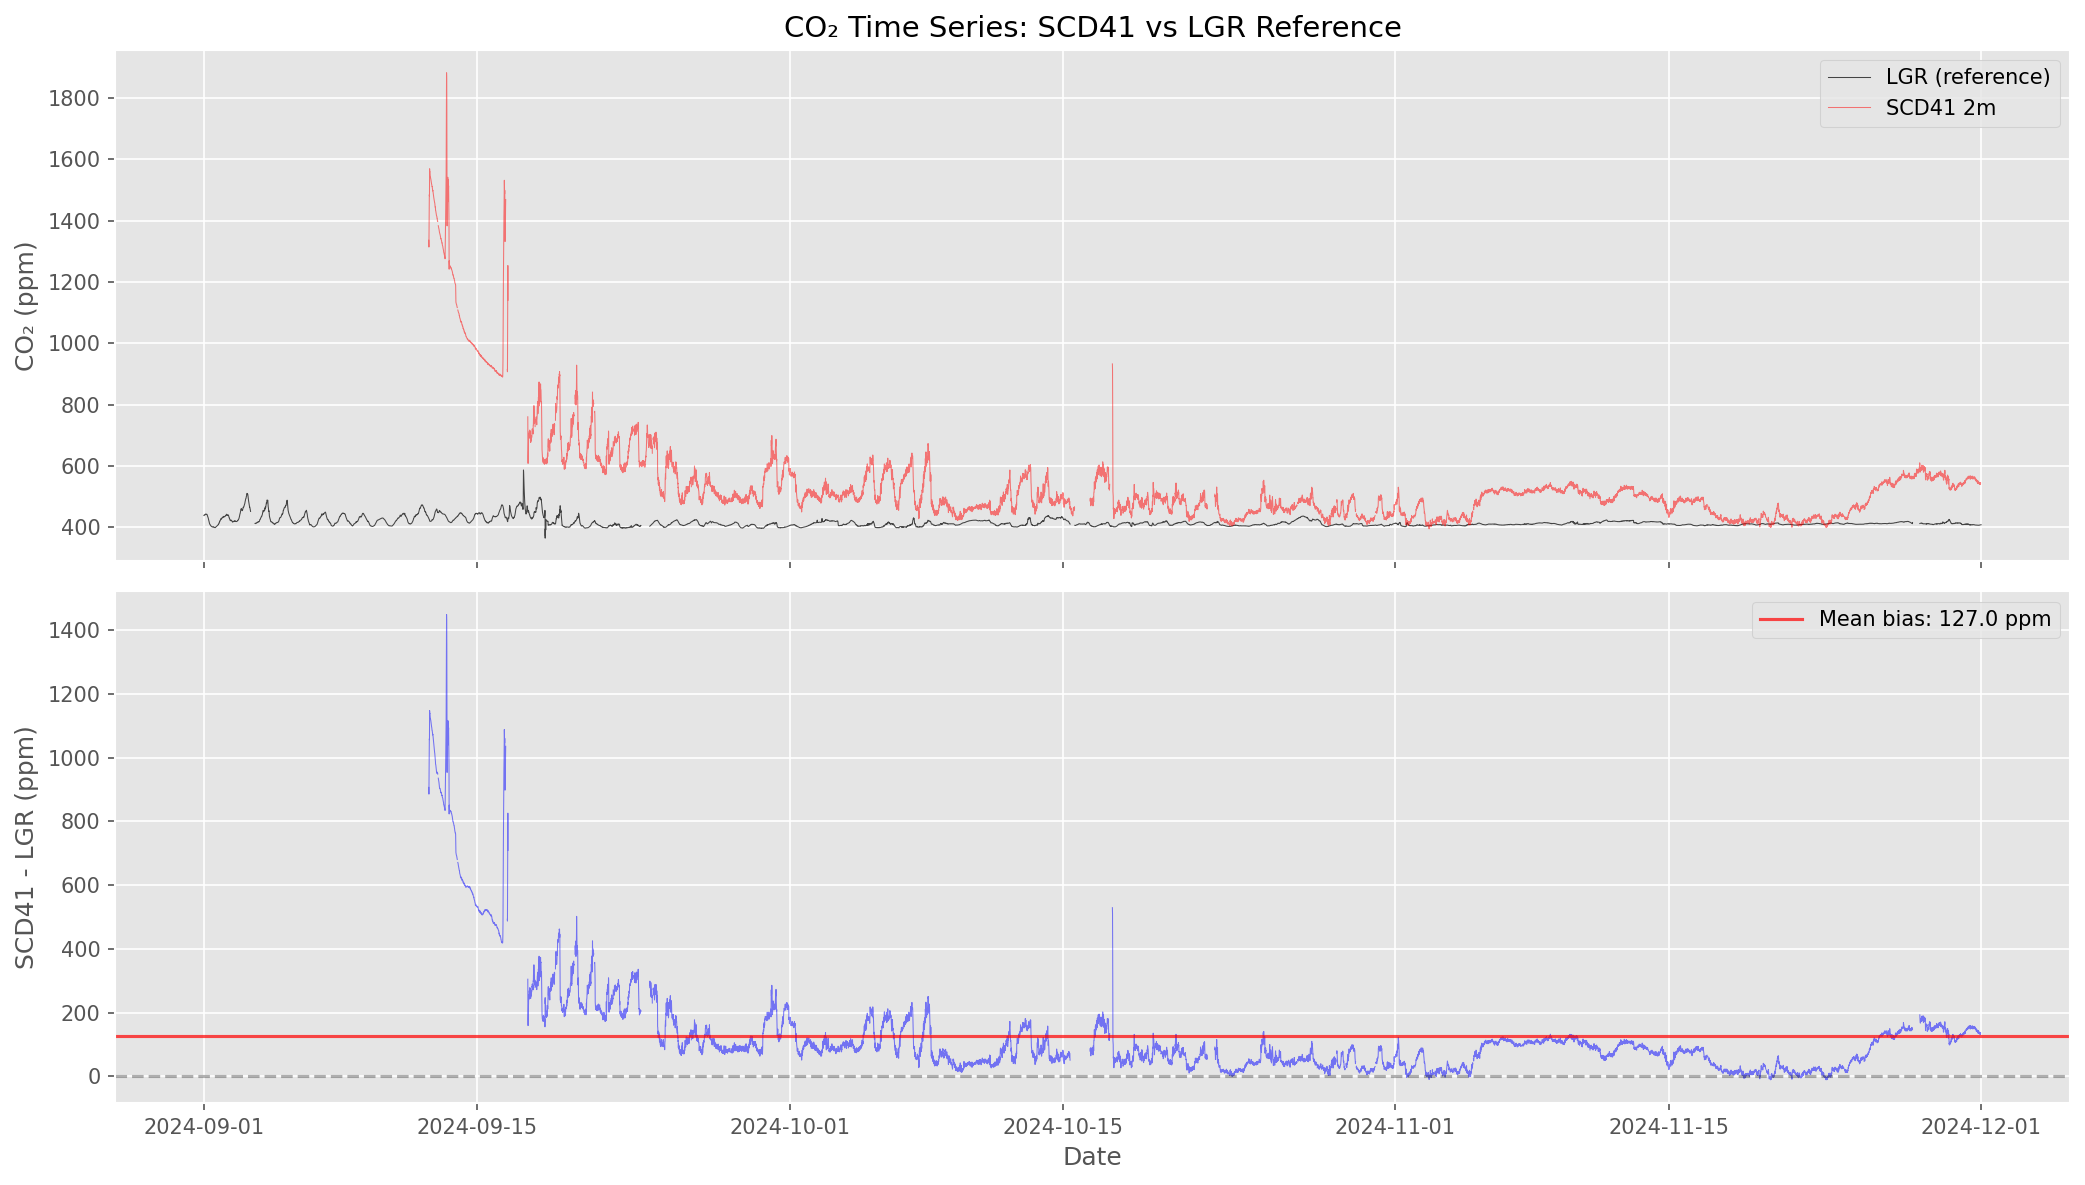

Mean bias: 127.0 ppm
RMSE: 204.6 ppm
Correlation: 0.519


In [8]:
import matplotlib.pyplot as plt
import pandas as pd

merged = pd.read_csv('output/merged/csv/SMEAR_EE_CO2_merged.csv', parse_dates=['timestamp'])

# Quick comparison: SCD41 2m vs LGR reference
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Time series
ax1 = axes[0]
ax1.plot(merged['timestamp'], merged['lgr_30m_CO2_dry_mean'], 'k-', alpha=0.7, label='LGR (reference)', linewidth=0.5)
ax1.plot(merged['timestamp'], merged['co2_sct1_2m_co2_mean'], 'r-', alpha=0.5, label='SCD41 2m', linewidth=0.5)
ax1.set_ylabel('CO₂ (ppm)')
ax1.legend()
ax1.set_title('CO₂ Time Series: SCD41 vs LGR Reference')

# Difference
ax2 = axes[1]
diff = merged['co2_sct1_2m_co2_mean'] - merged['lgr_30m_CO2_dry_mean']
ax2.plot(merged['timestamp'], diff, 'b-', alpha=0.5, linewidth=0.5)
ax2.axhline(0, color='k', linestyle='--', alpha=0.3)
ax2.axhline(diff.mean(), color='r', linestyle='-', alpha=0.7, label=f'Mean bias: {diff.mean():.1f} ppm')
ax2.set_ylabel('SCD41 - LGR (ppm)')
ax2.set_xlabel('Date')
ax2.legend()

plt.tight_layout()
plt.savefig('output/merged/plots/quick_comparison.png', dpi=300)
plt.show()

print(f"Mean bias: {diff.mean():.1f} ppm")
print(f"RMSE: {(diff**2).mean()**0.5:.1f} ppm")
print(f"Correlation: {merged['co2_sct1_2m_co2_mean'].corr(merged['lgr_30m_CO2_dry_mean']):.3f}")

### taylor plot dev

Reference (LGR) std: 13.44 ppm
SCD41 2m: std=97.9, r=0.331, CRMSD=94.5, n=52858
SCD41 30m-A: std=48.4, r=0.099, CRMSD=48.8, n=22425
SCD41 30m-B: std=95.7, r=0.014, CRMSD=96.2, n=18339
SCD41 30m-C: std=56.8, r=0.503, CRMSD=51.5, n=43392


/tmp/ipykernel_606990/1772101536.py:61: MatplotlibDeprecationWarning: Passing `apply_theta_transforms=True` (the default) is deprecated since Matplotlib 3.9. Support for this will be removed in Matplotlib in 3.11. To prevent this warning, set `apply_theta_transforms=False`, and make sure to shift theta values before being passed to this transform.
  tr = PolarAxes.PolarTransform()
/tmp/ipykernel_606990/1772101536.py:130: MatplotlibDeprecationWarning: Passing `apply_theta_transforms=True` (the default) is deprecated since Matplotlib 3.9. Support for this will be removed in Matplotlib in 3.11. To prevent this warning, set `apply_theta_transforms=False`, and make sure to shift theta values before being passed to this transform.
  ax_polar.clabel(contour, inline=True, fontsize=8, fmt=f'{rmsd:.0f}')


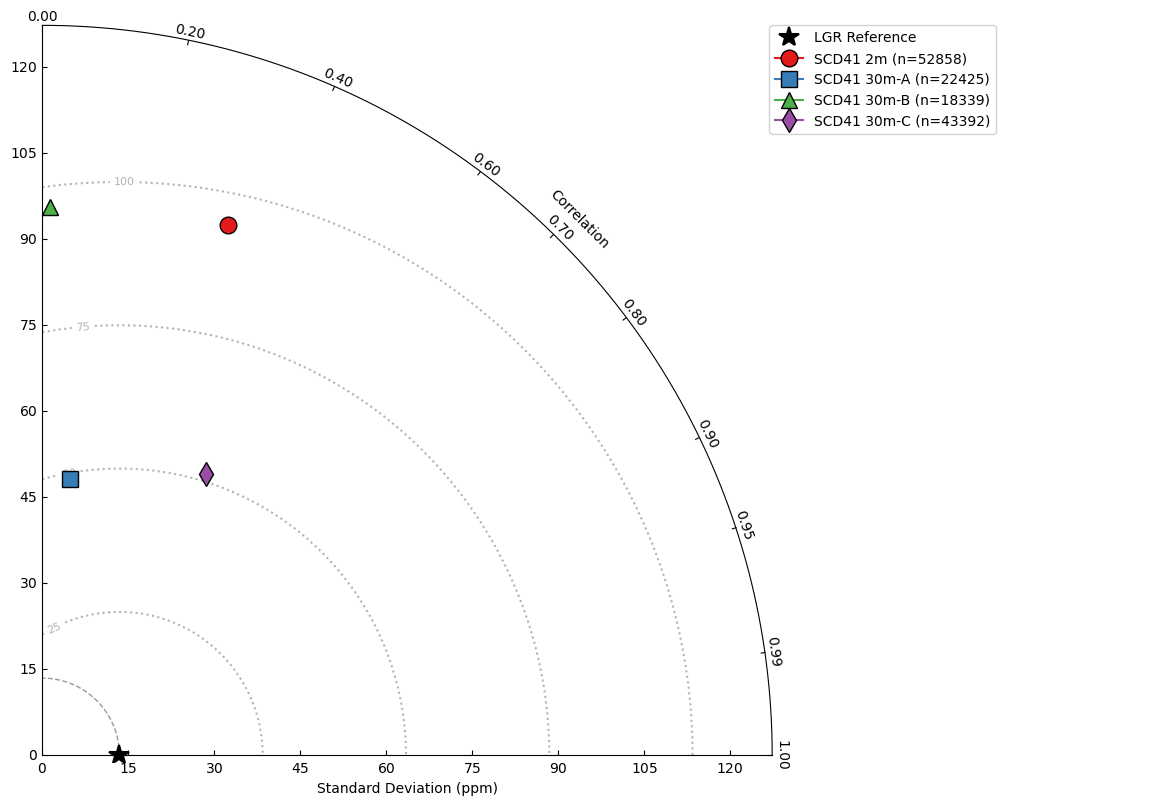


✓ Saved: output/plots/taylor_diagram.png


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.projections import PolarAxes
import mpl_toolkits.axisartist.floating_axes as FA
import mpl_toolkits.axisartist.grid_finder as GF

# Load merged data
merged = pd.read_csv('output/merged/csv/SMEAR_EE_CO2_merged.csv', parse_dates=['timestamp'], low_memory=False)

# Reference (LGR)
ref_col = 'lgr_30m_CO2_dry_mean'

# Test sensors
sensors = {
    'SCD41 2m': 'co2_sct1_2m_co2_mean',
    'SCD41 30m-A': 'co2_30m_a_co2_mean',
    'SCD41 30m-B': 'co2_30m_b_co2_mean',
    'SCD41 30m-C': 'co2_30m_c_co2_mean',
}

# Calculate statistics for each sensor
def calc_taylor_stats(ref, test):
    """Calculate std, correlation, and centered RMSD"""
    valid = ref.notna() & test.notna()
    if valid.sum() < 10:
        return None, None, None, 0
    
    r = ref[valid].values
    t = test[valid].values
    
    # Normalize by reference std for Taylor diagram
    ref_std = np.std(r, ddof=1)
    test_std = np.std(t, ddof=1)
    corr = np.corrcoef(r, t)[0, 1]
    
    # Centered RMSD
    r_anom = r - np.mean(r)
    t_anom = t - np.mean(t)
    crmsd = np.sqrt(np.mean((t_anom - r_anom)**2))
    
    return test_std, corr, crmsd, valid.sum()

# Get reference std
ref_data = merged[ref_col].dropna()
ref_std = ref_data.std()
print(f"Reference (LGR) std: {ref_std:.2f} ppm")

# Calculate stats for all sensors
stats = {}
for name, col in sensors.items():
    test_std, corr, crmsd, n = calc_taylor_stats(merged[ref_col], merged[col])
    if test_std is not None:
        stats[name] = {'std': test_std, 'corr': corr, 'crmsd': crmsd, 'n': n}
        print(f"{name}: std={test_std:.1f}, r={corr:.3f}, CRMSD={crmsd:.1f}, n={n}")

# ============ TAYLOR DIAGRAM ============
fig = plt.figure(figsize=(10, 9))

# Create polar axes (only right quadrant: 0-90 degrees)
tr = PolarAxes.PolarTransform()

# Correlation labels
rlocs = np.array([0, 0.2, 0.4, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99, 1.0])
tlocs = np.arccos(rlocs)
gl1 = GF.FixedLocator(tlocs)
tf1 = GF.DictFormatter(dict(zip(tlocs, map(lambda x: f'{x:.2f}', rlocs))))

# Std dev range (radial axis)
smax = max(ref_std, max(s['std'] for s in stats.values())) * 1.3
smin = 0

# Grid helper
ghelper = FA.GridHelperCurveLinear(
    tr,
    extremes=(0, np.pi/2, smin, smax),  # theta_min, theta_max, r_min, r_max
    grid_locator1=gl1,
    tick_formatter1=tf1,
)

ax = FA.FloatingSubplot(fig, 111, grid_helper=ghelper)
fig.add_subplot(ax)

# Adjust axes
ax.axis["top"].set_axis_direction("bottom")
ax.axis["top"].toggle(ticklabels=True, label=True)
ax.axis["top"].major_ticklabels.set_axis_direction("top")
ax.axis["top"].label.set_axis_direction("top")
ax.axis["top"].label.set_text("Correlation")

ax.axis["left"].set_axis_direction("bottom")
ax.axis["left"].label.set_text("Standard Deviation (ppm)")

ax.axis["right"].set_axis_direction("top")
ax.axis["right"].toggle(ticklabels=True)
ax.axis["right"].major_ticklabels.set_axis_direction("left")

ax.axis["bottom"].set_visible(False)

# Get the actual polar axes for plotting
ax_polar = ax.get_aux_axes(tr)

# Plot reference point
ax_polar.plot(0, ref_std, 'k*', markersize=15, label='LGR Reference', 
              markeredgecolor='black', markeredgewidth=1.5, zorder=10)

# Plot sensors
colors = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3']
markers = ['o', 's', '^', 'd']

for i, (name, s) in enumerate(stats.items()):
    theta = np.arccos(s['corr'])
    r = s['std']
    ax_polar.plot(theta, r, marker=markers[i], color=colors[i], 
                  markersize=12, label=f"{name} (n={s['n']})",
                  markeredgecolor='black', markeredgewidth=1, zorder=5)

# Add RMSD contours (centered on reference point)
angles = np.linspace(0, np.pi/2, 100)
for rmsd in [25, 50, 75, 100, 150, 200]:
    # RMSD² = σ_test² + σ_ref² - 2·σ_test·σ_ref·cos(θ)
    # Solve for r (σ_test) at each angle
    rs = np.linspace(0, smax, 100)
    ts = np.linspace(0, np.pi/2, 100)
    RS, TS = np.meshgrid(rs, ts)
    RMSD = np.sqrt(ref_std**2 + RS**2 - 2*ref_std*RS*np.cos(TS))
    
    contour = ax_polar.contour(TS, RS, RMSD, levels=[rmsd], 
                                colors='gray', linestyles=':', alpha=0.6)
    ax_polar.clabel(contour, inline=True, fontsize=8, fmt=f'{rmsd:.0f}')

# Add reference std arc
theta_arc = np.linspace(0, np.pi/2, 100)
ax_polar.plot(theta_arc, np.ones_like(theta_arc)*ref_std, 'k--', alpha=0.4, linewidth=1)

# Styling
ax_polar.set_title('Taylor Diagram: SCD41 Sensors vs LGR Reference\n', fontsize=14, fontweight='bold')
ax_polar.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0), frameon=True, framealpha=0.9)

plt.tight_layout()
plt.savefig('output/plots/taylor_diagram.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Saved: output/plots/taylor_diagram.png")

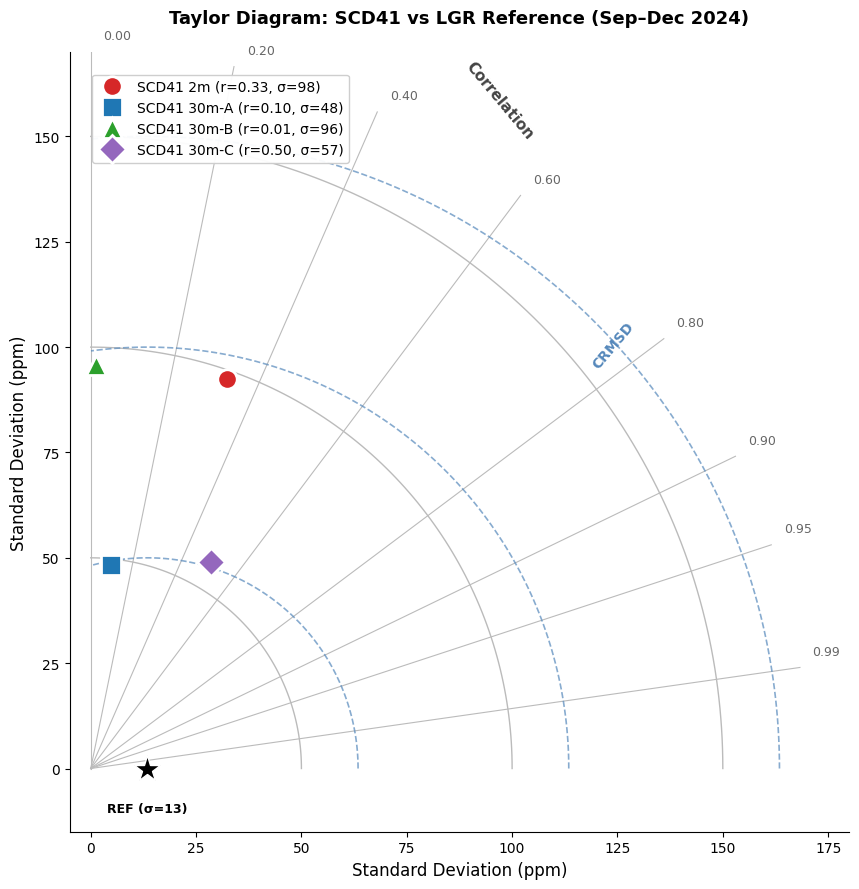

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load merged data
merged = pd.read_csv('output/merged/csv/SMEAR_EE_CO2_merged.csv', parse_dates=['timestamp'], low_memory=False)

# Reference and sensors
ref_col = 'lgr_30m_CO2_dry_mean'
sensors = {
    'SCD41 2m': 'co2_sct1_2m_co2_mean',
    'SCD41 30m-A': 'co2_30m_a_co2_mean',
    'SCD41 30m-B': 'co2_30m_b_co2_mean',
    'SCD41 30m-C': 'co2_30m_c_co2_mean',
}

# Calculate statistics
def calc_taylor_stats(ref, test):
    valid = ref.notna() & test.notna()
    if valid.sum() < 10:
        return None
    r, t = ref[valid].values, test[valid].values
    return {
        'std': np.std(t, ddof=1),
        'corr': np.corrcoef(r, t)[0, 1],
        'crmsd': np.sqrt(np.mean((t - t.mean() - (r - r.mean()))**2)),
        'n': valid.sum()
    }

ref_std = merged[ref_col].std()
stats = {name: calc_taylor_stats(merged[ref_col], merged[col]) 
         for name, col in sensors.items()}
stats = {k: v for k, v in stats.items() if v is not None}

# ============ CLEAN TAYLOR DIAGRAM ============
fig, ax = plt.subplots(figsize=(10, 9))

def polar_to_cart(std, corr):
    theta = np.arccos(np.clip(corr, -1, 1))
    return std * np.cos(theta), std * np.sin(theta)

smax = 170

# 1. Standard deviation arcs (from origin) - SOLID GRAY
for std_val in [50, 100, 150]:
    theta = np.linspace(0, np.pi/2, 100)
    ax.plot(std_val * np.cos(theta), std_val * np.sin(theta), 
            '-', color='#bbbbbb', linewidth=1, zorder=1)

# 2. Correlation lines (from origin) - SOLID GRAY
for corr in [0.0, 0.2, 0.4, 0.6, 0.8, 0.9, 0.95, 0.99]:
    theta = np.arccos(corr)
    x_end, y_end = smax * np.cos(theta), smax * np.sin(theta)
    ax.plot([0, x_end], [0, y_end], '-', color='#bbbbbb', linewidth=0.8, zorder=1)
    # Label at end
    ax.text(x_end + 3, y_end + 3, f'{corr:.2f}', fontsize=9, color='#666666', ha='left')

# 3. RMSD contours (from REFERENCE point) - DASHED BLUE
ref_x = ref_std
for rmsd in [50, 100, 150]:
    theta = np.linspace(0, np.pi, 200)
    x = ref_x + rmsd * np.cos(theta)
    y = rmsd * np.sin(theta)
    valid = (y >= 0) & (x >= 0) & (x <= smax) & (y <= smax)
    if valid.any():
        ax.plot(x[valid], y[valid], '--', color='#5588bb', linewidth=1.2, 
                alpha=0.7, zorder=2)

# 4. Reference point
ax.plot(ref_std, 0, 'k*', markersize=20, zorder=10, markeredgecolor='white', markeredgewidth=1)
ax.text(ref_std, -8, f'REF (σ={ref_std:.0f})', fontsize=9, ha='center', va='top', fontweight='bold')

# 5. Sensor points
colors = ['#d62728', '#1f77b4', '#2ca02c', '#9467bd']
markers = ['o', 's', '^', 'D']

for i, (name, s) in enumerate(stats.items()):
    x, y = polar_to_cart(s['std'], s['corr'])
    ax.plot(x, y, marker=markers[i], color=colors[i], 
            markersize=14, markeredgecolor='white', markeredgewidth=2,
            linestyle='', zorder=5, 
            label=f"{name} (r={s['corr']:.2f}, σ={s['std']:.0f})")

# Axes
ax.set_xlim(-5, smax + 10)
ax.set_ylim(-15, smax)
ax.set_aspect('equal')
ax.set_xlabel('Standard Deviation (ppm)', fontsize=12)
ax.set_ylabel('Standard Deviation (ppm)', fontsize=12)

# Labels - positioned to avoid overlap
ax.text(smax * 0.52, smax * 0.88, 'Correlation', fontsize=11, fontweight='bold',
        color='#444444', rotation=-50)
ax.text(ref_x + 105, 95, 'CRMSD', fontsize=10, color='#5588bb', fontweight='bold',
        rotation=50)

# Title
ax.set_title('Taylor Diagram: SCD41 vs LGR Reference (Sep–Dec 2024)\n', 
             fontsize=13, fontweight='bold')

# Legend - moved to upper left to avoid correlation labels
ax.legend(loc='upper left', frameon=True, framealpha=0.95, fontsize=10,
          bbox_to_anchor=(0.02, 0.98))

# Remove box
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('output/plots/taylor_diagram.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('output/plots/taylor_diagram.pdf', bbox_inches='tight')
plt.show()

In [9]:
# from src.taylor_diagram_custom import TaylorPlotter

# plotter = TaylorPlotter(output_dir=Path("output/plots"))

# # Simple: all sensors
# fig = plotter.plot_from_config(
#     config,
#     title="Taylor Diagram: SCD41 Sensors vs LGR Reference",
#     filename="taylor_all_sensors.png"
# )

# # Selective: only 30m sensors
# fig = plotter.plot_from_config(
#     config,
#     test_sensor_ids=['CO2_30M_A', 'CO2_30M_B', 'CO2_30M_C'],
#     title="Taylor Diagram: 30m Height Sensors",
#     filename="taylor_30m_only.png"
# )

from src.visualization import TaylorDiagram

taylor = TaylorDiagram(config.output_dir / "plots")
taylor.plot_from_config(config, normalize=True)

2026-01-27 18:28:34,666 - TaylorDiagram - INFO - Plotting from config: LGR_30M vs ['CO2_SCT1_2M', 'CO2_30M_A', 'CO2_30M_B', 'CO2_30M_C']
2026-01-27 18:28:34,667 - TaylorDiagram - INFO - Creating NORMALIZED Taylor diagram with 4 test sensors


FileNotFoundError: [Errno 2] No such file or directory: '/home/mbz/Documents/PhD/SCD41_DATA/output/sensors/LGR_30M_10min.csv'

### Generate all Plots

todo:
- tune plot aesthetic

In [ ]:
from src.visualization import generate_all_plots
# generate_all_plots(config, show=False, exclude=['uptime','co2','qc','monthly','comparison','difference','taylor'])
generate_all_plots(config, show=False, exclude=['taylor'])
# quiet — save only
# Exclude categories: uptime, qc, co2, monthly, uptime_summary, comparison, scatter, difference, taylor

2026-02-15 23:36:07,104 - src.visualization - INFO - Generating plots...
2026-02-15 23:36:07,106 - src.visualization - INFO -   Multi-sensor uptime summary
2026-02-15 23:36:07,513 - UptimePlots - INFO - Saved: uptime_summary_all_sensors.png
2026-02-15 23:36:07,514 - src.visualization - INFO -   CO2_SCT1_2M vs LGR_30M: Scatter
2026-02-15 23:36:07,886 - ValidationPlots - INFO - Saved: scatter_CO2_SCT1_2M_vs_LGR_30M.png
2026-02-15 23:36:07,888 - src.visualization - INFO -   CO2_30M_A vs LGR_30M: Scatter
2026-02-15 23:36:08,181 - ValidationPlots - INFO - Saved: scatter_CO2_30M_A_vs_LGR_30M.png
2026-02-15 23:36:08,183 - src.visualization - INFO -   CO2_30M_B vs LGR_30M: Scatter
2026-02-15 23:36:08,472 - ValidationPlots - INFO - Saved: scatter_CO2_30M_B_vs_LGR_30M.png
2026-02-15 23:36:08,475 - src.visualization - INFO -   CO2_30M_C vs LGR_30M: Scatter
2026-02-15 23:36:08,780 - ValidationPlots - INFO - Saved: scatter_CO2_30M_C_vs_LGR_30M.png
2026-02-15 23:36:08,781 - src.visualization - INFO 